In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
df = pd.read_csv("Delivery_Logistics_Week2_Preprocessed.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,delivery_time_hours,...,delayed,delivery_status,delivery_rating,delivery_cost,delivery_time_outlier,distance_km_normalized,package_weight_kg_normalized,delivery_time_hours_normalized,expected_time_hours_normalized,delivery_cost_normalized
0,1,delhivery,automobile parts,bike,same day,west,clear,297.0,46.96,8,...,no,delivered,3,1632.7206,False,0.999659,0.947595,0.421053,0.272727,1.000000
1,2,xpressbees,cosmetics,ev van,express,central,cold,89.6,47.39,2,...,no,delivered,5,640.1700,False,0.293015,0.956397,0.105263,0.045455,0.354251
2,3,shadowfax,groceries,truck,two day,east,rainy,273.5,26.89,10,...,no,delivered,4,1448.1700,False,0.919591,0.536745,0.526316,0.636364,0.879932
3,4,dhl,electronics,ev van,same day,east,cold,269.7,12.69,6,...,no,delivered,3,1486.5700,False,0.906644,0.246059,0.315789,0.272727,0.904915
4,5,dhl,clothing,van,two day,north,foggy,256.7,37.02,9,...,no,delivered,4,1394.5600,False,0.862351,0.744115,0.473684,0.636364,0.845054


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (25000, 21)

Column Names:
['delivery_id', 'delivery_partner', 'package_type', 'vehicle_type', 'delivery_mode', 'region', 'weather_condition', 'distance_km', 'package_weight_kg', 'delivery_time_hours', 'expected_time_hours', 'delayed', 'delivery_status', 'delivery_rating', 'delivery_cost', 'delivery_time_outlier', 'distance_km_normalized', 'package_weight_kg_normalized', 'delivery_time_hours_normalized', 'expected_time_hours_normalized', 'delivery_cost_normalized']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 21 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   delivery_id                     25000 non-null  int64  
 1   delivery_partner                25000 non-null  str    
 2   package_type                    25000 non-null  str    
 3   vehicle_type                    25000 non-null  str    
 4   delivery_mode           

In [6]:
df.describe()

,delivery_id,distance_km,package_weight_kg,delivery_time_hours,expected_time_hours,delivery_rating,delivery_cost,distance_km_normalized,package_weight_kg_normalized,delivery_time_hours_normalized,expected_time_hours_normalized,delivery_cost_normalized
count,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000
mean,12500.500000,150.390436,25.145898,6.248040,13.107680,3.666000,864.944579,0.500138,0.501042,0.328844,0.504895,0.500488
std,7217.022701,86.409745,14.368663,3.140935,7.559024,1.149964,435.712593,0.294411,0.294138,0.165312,0.343592,0.283473
min,1.000000,3.600000,0.670000,0.000000,2.000000,1.000000,95.667400,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6250.750000,75.900000,12.680000,4.000000,8.000000,3.000000,490.800000,0.246337,0.245855,0.210526,0.272727,0.257072
50%,12500.500000,151.000000,25.145000,6.000000,8.000000,4.000000,867.535000,0.502215,0.501024,0.315789,0.272727,0.502174
75%,18750.250000,224.900000,37.660000,8.000000,16.000000,5.000000,1237.910000,0.754003,0.757216,0.421053,0.636364,0.743138
max,25000.000000,297.100000,49.520000,19.000000,24.000000,5.000000,1632.720600,1.000000,1.000000,1.000000,1.000000,1.000000


In [7]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
delivery_id,25000.0,12500.500000,7217.022701,1.0000,6250.750000,12500.500000,18750.250000,25000.0000
distance_km,25000.0,150.390436,86.409745,3.6000,75.900000,151.000000,224.900000,297.1000
package_weight_kg,25000.0,25.145898,14.368663,0.6700,12.680000,25.145000,37.660000,49.5200
delivery_time_hours,25000.0,6.248040,3.140935,0.0000,4.000000,6.000000,8.000000,19.0000
expected_time_hours,25000.0,13.107680,7.559024,2.0000,8.000000,8.000000,16.000000,24.0000
delivery_rating,25000.0,3.666000,1.149964,1.0000,3.000000,4.000000,5.000000,5.0000
delivery_cost,25000.0,864.944579,435.712593,95.6674,490.800000,867.535000,1237.910000,1632.7206
distance_km_normalized,25000.0,0.500138,0.294411,0.0000,0.246337,0.502215,0.754003,1.0000
package_weight_kg_normalized,25000.0,0.501042,0.294138,0.0000,0.245855,0.501024,0.757216,1.0000
delivery_time_hours_normalized,25000.0,0.328844,0.165312,0.0000,0.210526,0.315789,0.421053,1.0000


In [8]:
print("Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nZero Delivery Time Records:")
print((df['delivery_time_hours'] == 0).sum())

print("\nNegative Delivery Time Records:")
print((df['delivery_time_hours'] < 0).sum())

Missing Values:
0

Duplicate Records:
0

Zero Delivery Time Records:
255

Negative Delivery Time Records:
0


In [9]:
zero_delivery = df[df['delivery_time_hours'] == 0]

print("Zero Delivery Time Records:")
display(zero_delivery.head(10))

Zero Delivery Time Records:


,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,delivery_time_hours,...,delayed,delivery_status,delivery_rating,delivery_cost,delivery_time_outlier,distance_km_normalized,package_weight_kg_normalized,delivery_time_hours_normalized,expected_time_hours_normalized,delivery_cost_normalized
87,88,ekart,furniture,van,two day,south,cold,3.6,8.75,0,...,no,delivered,3,95.6674,False,0.000000,0.165404,0.0,0.636364,0.000000
136,137,shadowfax,groceries,ev bike,same day,west,hot,8.7,33.93,0,...,no,delivered,5,245.2900,False,0.017376,0.680860,0.0,0.272727,0.097344
181,182,blue dart,pharmacy,truck,same day,east,hot,9.9,30.24,0,...,no,delivered,3,240.2200,False,0.021465,0.605322,0.0,0.272727,0.094045
303,304,ecom express,cosmetics,bike,same day,east,hot,21.0,8.00,0,...,no,delivered,4,229.0000,False,0.059284,0.150051,0.0,0.272727,0.086746
574,575,delhivery,fragile items,bike,express,east,clear,41.7,27.97,0,...,no,delivered,5,342.4100,False,0.129813,0.558854,0.0,0.000000,0.160530
823,824,shadowfax,documents,ev van,same day,north,cold,13.2,26.57,0,...,no,delivered,3,245.7100,False,0.032709,0.530194,0.0,0.272727,0.097617
836,837,amazon logistics,automobile parts,bike,two day,central,cold,24.5,35.61,0,...,no,delivered,4,229.3300,False,0.071210,0.715251,0.0,0.636364,0.086960
871,872,blue dart,documents,ev van,same day,central,hot,33.3,48.50,0,...,no,delivered,5,412.0000,False,0.101193,0.979120,0.0,0.272727,0.205805
947,948,blue dart,fragile items,scooter,standard,west,hot,9.0,5.43,0,...,no,delivered,4,95.6674,False,0.018399,0.097441,0.0,1.000000,0.000000
1046,1047,ekart,pharmacy,scooter,same day,central,clear,10.5,33.60,0,...,no,delivered,3,253.3000,False,0.023509,0.674104,0.0,0.272727,0.102555


In [10]:
print(zero_delivery['delivery_status'].value_counts())

print("\nDelayed Status:")
print(zero_delivery['delayed'].value_counts())

delivery_status
delivered    255
Name: count, dtype: int64

Delayed Status:
delayed
no    255
Name: count, dtype: int64


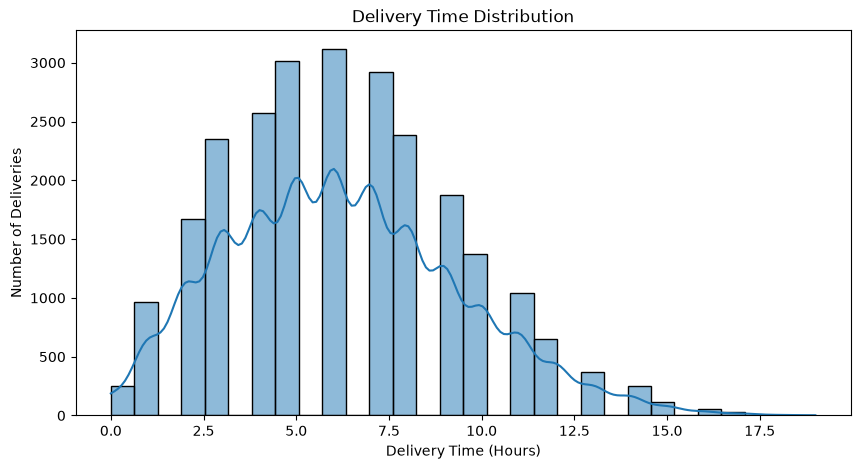

In [11]:
plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x='delivery_time_hours',
    bins=30,
    kde=True
)

plt.title('Delivery Time Distribution')
plt.xlabel('Delivery Time (Hours)')
plt.ylabel('Number of Deliveries')

plt.show()

In [12]:
zero_delivery = df[df['delivery_time_hours'] == 0]

display(zero_delivery.head(10))

,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,delivery_time_hours,...,delayed,delivery_status,delivery_rating,delivery_cost,delivery_time_outlier,distance_km_normalized,package_weight_kg_normalized,delivery_time_hours_normalized,expected_time_hours_normalized,delivery_cost_normalized
87,88,ekart,furniture,van,two day,south,cold,3.6,8.75,0,...,no,delivered,3,95.6674,False,0.000000,0.165404,0.0,0.636364,0.000000
136,137,shadowfax,groceries,ev bike,same day,west,hot,8.7,33.93,0,...,no,delivered,5,245.2900,False,0.017376,0.680860,0.0,0.272727,0.097344
181,182,blue dart,pharmacy,truck,same day,east,hot,9.9,30.24,0,...,no,delivered,3,240.2200,False,0.021465,0.605322,0.0,0.272727,0.094045
303,304,ecom express,cosmetics,bike,same day,east,hot,21.0,8.00,0,...,no,delivered,4,229.0000,False,0.059284,0.150051,0.0,0.272727,0.086746
574,575,delhivery,fragile items,bike,express,east,clear,41.7,27.97,0,...,no,delivered,5,342.4100,False,0.129813,0.558854,0.0,0.000000,0.160530
823,824,shadowfax,documents,ev van,same day,north,cold,13.2,26.57,0,...,no,delivered,3,245.7100,False,0.032709,0.530194,0.0,0.272727,0.097617
836,837,amazon logistics,automobile parts,bike,two day,central,cold,24.5,35.61,0,...,no,delivered,4,229.3300,False,0.071210,0.715251,0.0,0.636364,0.086960
871,872,blue dart,documents,ev van,same day,central,hot,33.3,48.50,0,...,no,delivered,5,412.0000,False,0.101193,0.979120,0.0,0.272727,0.205805
947,948,blue dart,fragile items,scooter,standard,west,hot,9.0,5.43,0,...,no,delivered,4,95.6674,False,0.018399,0.097441,0.0,1.000000,0.000000
1046,1047,ekart,pharmacy,scooter,same day,central,clear,10.5,33.60,0,...,no,delivered,3,253.3000,False,0.023509,0.674104,0.0,0.272727,0.102555


In [13]:
print("Delivery Status:")
print(zero_delivery['delivery_status'].value_counts())

print("\nDelayed Status:")
print(zero_delivery['delayed'].value_counts())

Delivery Status:
delivery_status
delivered    255
Name: count, dtype: int64

Delayed Status:
delayed
no    255
Name: count, dtype: int64


In [14]:
print("Delivery Time Outliers:")
print(df['delivery_time_outlier'].value_counts())

print("\nOutlier Percentage:")
print(
    df['delivery_time_outlier'].value_counts(normalize=True) * 100
)

Delivery Time Outliers:
delivery_time_outlier
False    24797
True       203
Name: count, dtype: int64

Outlier Percentage:
delivery_time_outlier
False    99.188
True      0.812
Name: proportion, dtype: float64


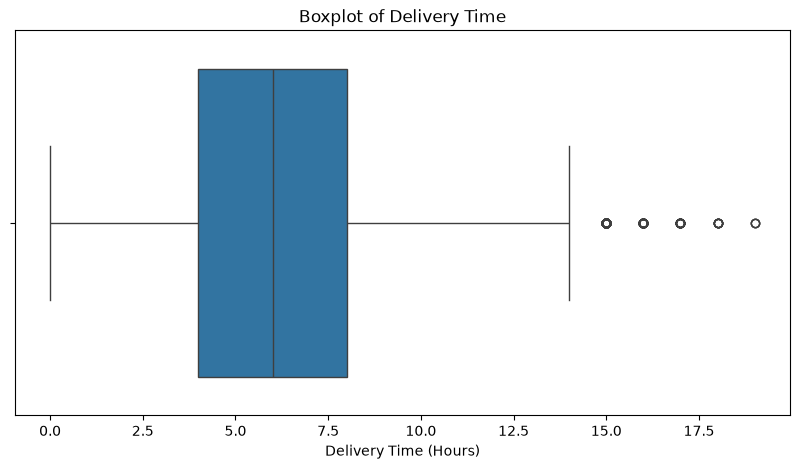

In [15]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['delivery_time_hours'])

plt.title("Boxplot of Delivery Time")
plt.xlabel("Delivery Time (Hours)")

plt.show()

In [16]:
categorical_columns = df.select_dtypes(
    include=['object', 'str']
).columns

for col in categorical_columns:
    print("\n", col)
    print(df[col].value_counts())


 delivery_partner
delivery_partner
xpressbees          2826
fedex               2818
dhl                 2802
ekart               2801
blue dart           2798
delhivery           2786
shadowfax           2736
ecom express        2722
amazon logistics    2711
Name: count, dtype: int64

 package_type
package_type
fragile items       2848
pharmacy            2810
documents           2805
automobile parts    2795
electronics         2792
clothing            2767
furniture           2746
cosmetics           2744
groceries           2693
Name: count, dtype: int64

 vehicle_type
vehicle_type
ev bike    4218
van        4187
scooter    4174
bike       4160
truck      4145
ev van     4116
Name: count, dtype: int64

 delivery_mode
delivery_mode
two day     6302
same day    6279
express     6233
standard    6186
Name: count, dtype: int64

 region
region
west       5095
central    5060
south      4977
north      4949
east       4919
Name: count, dtype: int64

 weather_condition
weather_condition


In [17]:
features = [
    'delivery_partner',
    'package_type',
    'vehicle_type',
    'delivery_mode',
    'region',
    'weather_condition',
    'distance_km',
    'package_weight_kg',
    'expected_time_hours'
]

target = 'delivery_time_hours'

X = df[features]
y = df[target]

print("Independent Variables (X):")
print(X.columns.tolist())

print("\nDependent Variable (y):")
print(target)

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

Independent Variables (X):
['delivery_partner', 'package_type', 'vehicle_type', 'delivery_mode', 'region', 'weather_condition', 'distance_km', 'package_weight_kg', 'expected_time_hours']

Dependent Variable (y):
delivery_time_hours

X Shape: (25000, 9)
y Shape: (25000,)


In [18]:
print("Feature Data Types:")
print(X.dtypes)

print("\nTarget Data Type:")
print(y.dtype)

Feature Data Types:
delivery_partner           str
package_type               str
vehicle_type               str
delivery_mode              str
region                     str
weather_condition          str
distance_km            float64
package_weight_kg      float64
expected_time_hours      int64
dtype: object

Target Data Type:
int64


In [19]:
print("Missing Values in X:")
print(X.isnull().sum())

print("\nMissing Values in Target:")
print(y.isnull().sum())

Missing Values in X:
delivery_partner       0
package_type           0
vehicle_type           0
delivery_mode          0
region                 0
weather_condition      0
distance_km            0
package_weight_kg      0
expected_time_hours    0
dtype: int64

Missing Values in Target:
0


In [20]:
zero_delivery = df[df['delivery_time_hours'] == 0]

print("Total Zero Time Records:", len(zero_delivery))

print("\nDistance Statistics:")
print(zero_delivery['distance_km'].describe())

print("\nExpected Time Statistics:")
print(zero_delivery['expected_time_hours'].describe())

print("\nPackage Weight Statistics:")
print(zero_delivery['package_weight_kg'].describe())

Total Zero Time Records: 255

Distance Statistics:
count    255.000000
mean      15.386275
std       10.617910
min        3.600000
25%        6.250000
50%       13.400000
75%       21.950000
max       47.000000
Name: distance_km, dtype: float64

Expected Time Statistics:
count    255.000000
mean      12.541176
std        7.960858
min        2.000000
25%        8.000000
50%        8.000000
75%       16.000000
max       24.000000
Name: expected_time_hours, dtype: float64

Package Weight Statistics:
count    255.000000
mean      26.181098
std       14.664126
min        0.670000
25%       13.465000
50%       27.990000
75%       38.260000
max       49.520000
Name: package_weight_kg, dtype: float64


In [21]:
comparison = df.groupby(
    df['delivery_time_hours'] == 0
)[['distance_km', 'package_weight_kg',
   'expected_time_hours']].mean()

comparison.index = ['Normal Deliveries', 'Zero-Time Deliveries']

display(comparison)

,distance_km,package_weight_kg,expected_time_hours
Normal Deliveries,151.781669,25.135230,13.113518
Zero-Time Deliveries,15.386275,26.181098,12.541176


In [22]:
df_model = df[df['delivery_time_hours'] > 0].copy()

print("Original Dataset:", df.shape)
print("Modeling Dataset:", df_model.shape)

print("Removed Records:", len(df) - len(df_model))

Original Dataset: (25000, 21)
Modeling Dataset: (24745, 21)
Removed Records: 255


In [23]:
features = [
    'delivery_partner',
    'package_type',
    'vehicle_type',
    'delivery_mode',
    'region',
    'weather_condition',
    'distance_km',
    'package_weight_kg',
    'expected_time_hours'
]

target = 'delivery_time_hours'

X = df_model[features]
y = df_model[target]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (24745, 9)
y Shape: (24745,)


In [24]:
print("Minimum Delivery Time:", y.min())
print("Zero Delivery Time Records:", (y == 0).sum())
print("Missing Target Values:", y.isnull().sum())

Minimum Delivery Time: 1
Zero Delivery Time Records: 0
Missing Target Values: 0


In [25]:
from sklearn.preprocessing import OneHotEncoder

print("OneHotEncoder imported successfully!")

OneHotEncoder imported successfully!


In [26]:
categorical_features = [
    'delivery_partner',
    'package_type',
    'vehicle_type',
    'delivery_mode',
    'region',
    'weather_condition'
]

numerical_features = [
    'distance_km',
    'package_weight_kg',
    'expected_time_hours'
]

print("Categorical Features:", len(categorical_features))
print("Numerical Features:", len(numerical_features))

Categorical Features: 6
Numerical Features: 3


In [27]:
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

encoded_data = encoder.fit_transform(
    X[categorical_features]
)

print("Original Categorical Shape:",
      X[categorical_features].shape)

print("Encoded Data Shape:", encoded_data.shape)

Original Categorical Shape: (24745, 6)
Encoded Data Shape: (24745, 39)


In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (19796, 9)
Testing Features: (4949, 9)
Training Target: (19796,)
Testing Target: (4949,)


In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('numerical', StandardScaler(), numerical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [30]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Create Linear Regression pipeline
linear_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# Train the model
linear_model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [31]:
# Predict delivery time on test data
y_pred_linear = linear_model.predict(X_test)

print("First 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred_linear[:10])

First 10 Actual Values:
[ 5  3  5 16  5  9 10 11  6  7]

First 10 Predicted Values:
[ 6.82622342  1.95257824  3.91253862 10.06568716  6.02353027  8.89479778
 10.57010068  9.49913941  4.54907517  7.20309961]


In [32]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_linear = mean_absolute_error(y_test, y_pred_linear)

rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))

r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Performance")
print("MAE:", mae_linear)
print("RMSE:", rmse_linear)
print("R2 Score:", r2_linear)

Linear Regression Performance
MAE: 1.302027416790674
RMSE: 1.6332999721388894
R2 Score: 0.717260386231427


In [33]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline

# Create Decision Tree pipeline
dt_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(random_state=42))
])

# Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [34]:
# Predict delivery time using Decision Tree
y_pred_dt = dt_model.predict(X_test)

print("First 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred_dt[:10])

First 10 Actual Values:
[ 5  3  5 16  5  9 10 11  6  7]

First 10 Predicted Values:
[10.  2.  3.  8.  7. 11. 12. 10.  5. 10.]


In [35]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_dt = mean_absolute_error(y_test, y_pred_dt)

rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))

r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree Performance")
print("MAE:", mae_dt)
print("RMSE:", rmse_dt)
print("R2 Score:", r2_dt)

Decision Tree Performance
MAE: 1.7888462315619318
RMSE: 2.3348242597904196
R2 Score: 0.4222191474150683


In [46]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# Create Random Forest pipeline
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [47]:
# Predict delivery time using Random Forest
y_pred_rf = rf_model.predict(X_test)

print("First 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred_rf[:10])

First 10 Actual Values:
[ 5  3  5 16  5  9 10 11  6  7]

First 10 Predicted Values:
[7.27 2.02 3.52 9.79 5.79 8.15 9.96 9.17 4.56 7.19]


In [48]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Performance")
print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R2 Score:", r2_rf)

Random Forest Performance
MAE: 1.35139017983431
RMSE: 1.7016689595596655
R2 Score: 0.6930943350283334


In [49]:
import pandas as pd

model_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree', 'Random Forest'],
    'MAE': [mae_linear, mae_dt, mae_rf],
    'RMSE': [rmse_linear, rmse_dt, rmse_rf],
    'R2 Score': [r2_linear, r2_dt, r2_rf]
})

model_comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.302027,1.633300,0.717260
1,Decision Tree,1.788846,2.334824,0.422219
2,Random Forest,1.351390,1.701669,0.693094


In [50]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    linear_model,
    X,
    y,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

cv_rmse = -cv_scores

print("Cross-Validation RMSE Scores:", cv_rmse)
print("Average CV RMSE:", cv_rmse.mean())
print("Standard Deviation:", cv_rmse.std())

Cross-Validation RMSE Scores: [1.58723397 1.62361992 1.61789523 1.6519862  1.61150978]
Average CV RMSE: 1.6184490180105535
Standard Deviation: 0.020853390433987623


In [51]:
from sklearn.model_selection import GridSearchCV

dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', DecisionTreeRegressor(random_state=42))
])

param_grid = {
    'model__max_depth': [5, 10, 15, 20, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=dt_pipeline,
    param_grid=param_grid,
    cv=3,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV RMSE:", -grid_search.best_score_)

Best Parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2}
Best CV RMSE: 1.6832763832866418


In [52]:
best_dt_model = grid_search.best_estimator_

y_pred_best_dt = best_dt_model.predict(X_test)

mae_best_dt = mean_absolute_error(y_test, y_pred_best_dt)
rmse_best_dt = np.sqrt(mean_squared_error(y_test, y_pred_best_dt))
r2_best_dt = r2_score(y_test, y_pred_best_dt)

print("Tuned Decision Tree Performance")
print("MAE:", mae_best_dt)
print("RMSE:", rmse_best_dt)
print("R2 Score:", r2_best_dt)

Tuned Decision Tree Performance
MAE: 1.362424468372097
RMSE: 1.6998437605832937
R2 Score: 0.6937523519573446


In [53]:
final_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Decision Tree',
        'Random Forest',
        'Tuned Decision Tree'
    ],
    'MAE': [
        mae_linear,
        mae_dt,
        mae_rf,
        mae_best_dt
    ],
    'RMSE': [
        rmse_linear,
        rmse_dt,
        rmse_rf,
        rmse_best_dt
    ],
    'R2 Score': [
        r2_linear,
        r2_dt,
        r2_rf,
        r2_best_dt
    ]
})

final_comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.302027,1.633300,0.717260
1,Decision Tree,1.788846,2.334824,0.422219
2,Random Forest,1.351390,1.701669,0.693094
3,Tuned Decision Tree,1.362424,1.699844,0.693752


In [54]:
# Random Forest pipeline se trained model aur preprocessor lena
rf_trained = rf_model.named_steps['model']
rf_preprocessor = rf_model.named_steps['preprocessor']

# Encoded feature names
feature_names = rf_preprocessor.get_feature_names_out()

# Feature importance
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_trained.feature_importances_
})

# Highest importance first
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

importance_df.head(15)

,Feature,Importance
39,numerical__distance_km,0.523840
38,categorical__weather_condition_stormy,0.139520
37,categorical__weather_condition_rainy,0.085976
40,numerical__package_weight_kg,0.058066
35,categorical__weather_condition_foggy,0.037545
41,numerical__expected_time_hours,0.008517
30,categorical__region_north,0.005032
19,categorical__vehicle_type_ev bike,0.004843
28,categorical__region_central,0.004786
31,categorical__region_south,0.004703


In [55]:
importance_df['Original_Feature'] = (
    importance_df['Feature']
    .str.replace('categorical__', '', regex=False)
    .str.replace('numerical__', '', regex=False)
    .str.replace(r'_[^_]+$', '', regex=True)
)

original_importance = (
    importance_df
    .groupby('Original_Feature')['Importance']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

original_importance

,Original_Feature,Importance
0,distance,0.523840
1,weather_condition,0.268459
2,package_weight,0.058066
3,delivery_partner,0.038027
4,package_type,0.037871
5,vehicle_type,0.027758
6,region,0.023854
7,delivery_mode,0.013609
8,expected_time,0.008517


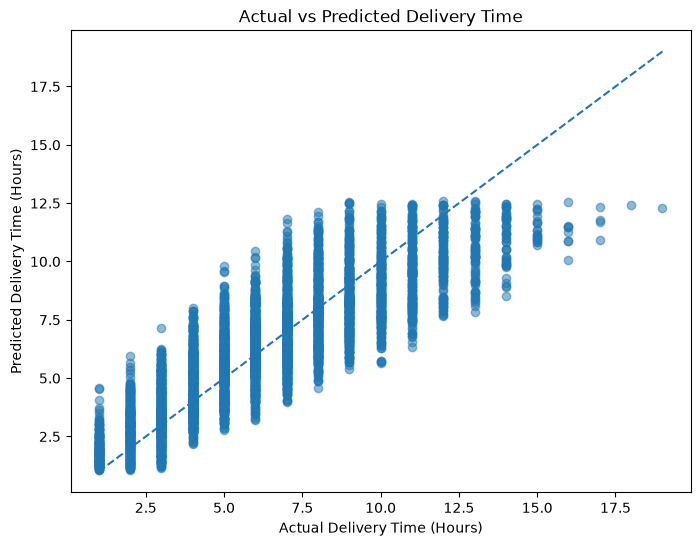

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_linear, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual Delivery Time (Hours)")
plt.ylabel("Predicted Delivery Time (Hours)")
plt.title("Actual vs Predicted Delivery Time")

plt.show()

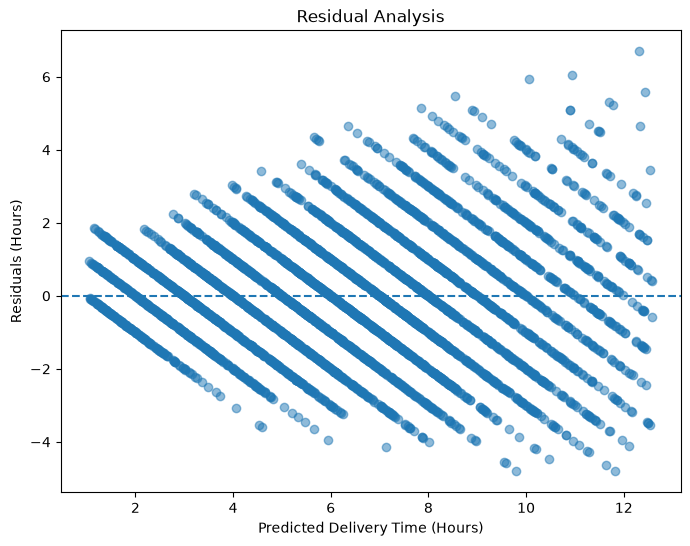

In [57]:
residuals = y_test - y_pred_linear

plt.figure(figsize=(8, 6))

plt.scatter(y_pred_linear, residuals, alpha=0.5)

plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted Delivery Time (Hours)")
plt.ylabel("Residuals (Hours)")
plt.title("Residual Analysis")

plt.show()

In [58]:
vehicle_analysis = df_model.groupby('vehicle_type').agg(
    Total_Deliveries=('delivery_id', 'count'),
    Average_Distance=('distance_km', 'mean'),
    Average_Package_Weight=('package_weight_kg', 'mean'),
    Average_Delivery_Time=('delivery_time_hours', 'mean'),
    Average_Delivery_Cost=('delivery_cost', 'mean'),
    Delay_Rate=('delayed', lambda x: (x == 'yes').mean() * 100)
).round(2)

vehicle_analysis

,Total_Deliveries,Average_Distance,Average_Package_Weight,Average_Delivery_Time,Average_Delivery_Cost,Delay_Rate
vehicle_type,,,,,,
bike,4115,152.89,25.06,6.35,876.33,27.34
ev bike,4168,152.68,25.41,6.27,877.21,26.75
ev van,4065,152.36,25.00,6.33,874.50,26.96
scooter,4136,151.41,24.62,6.34,869.06,26.38
truck,4117,151.20,25.40,6.26,869.25,27.23
van,4144,150.15,25.33,6.33,864.45,27.05


In [59]:
region_analysis = df_model.groupby('region').agg(
    Total_Deliveries=('delivery_id', 'count'),
    Average_Distance=('distance_km', 'mean'),
    Average_Delivery_Time=('delivery_time_hours', 'mean'),
    Average_Delivery_Cost=('delivery_cost', 'mean'),
    Delay_Rate=('delayed', lambda x: (x == 'yes').mean() * 100)
).round(2)

region_analysis

,Total_Deliveries,Average_Distance,Average_Delivery_Time,Average_Delivery_Cost,Delay_Rate
region,,,,,
central,4997,152.74,6.36,878.15,27.60
east,4879,150.95,6.26,866.88,26.01
north,4899,150.94,6.31,867.20,26.84
south,4929,150.47,6.26,864.80,27.04
west,5041,153.74,6.36,881.58,27.24


In [61]:
weather_analysis = df_model.groupby('weather_condition').agg(
    Total_Deliveries=('delivery_id', 'count'),
    Average_Distance=('distance_km', 'mean'),
    Average_Delivery_Time=('delivery_time_hours', 'mean'),
    Average_Delivery_Cost=('delivery_cost', 'mean'),
    Delay_Rate=('delayed', lambda x: (x == 'yes').mean() * 100)
).round(2)

weather_analysis

,Total_Deliveries,Average_Distance,Average_Delivery_Time,Average_Delivery_Cost,Delay_Rate
weather_condition,,,,,
clear,4025,153.82,4.89,881.72,17.86
cold,4076,153.43,4.87,880.16,16.34
foggy,4217,150.10,6.49,863.01,30.33
hot,4058,153.27,4.87,880.11,17.42
rainy,4171,150.98,7.80,867.47,37.35
stormy,4198,149.27,8.81,859.25,41.45


In [62]:
cost_analysis = df_model.groupby(
    ['vehicle_type', 'weather_condition']
).agg(
    Total_Deliveries=('delivery_id', 'count'),
    Average_Cost=('delivery_cost', 'mean'),
    Average_Distance=('distance_km', 'mean'),
    Average_Delivery_Time=('delivery_time_hours', 'mean')
).round(2)

cost_analysis.sort_values(
    by='Average_Cost',
    ascending=False
).head(15)

Total_Deliveries  Average_Cost  \
vehicle_type weather_condition                                   
ev van       hot                             636        906.50   
truck        clear                           694        899.79   
bike         hot                             681        899.41   
scooter      cold                            679        893.33   
ev bike      clear                           635        891.77   
bike         cold                            643        891.68   
ev bike      hot                             727        890.86   
             stormy                          679        885.32   
scooter      rainy                           702        884.51   
ev bike      cold                            689        881.57   
bike         clear                           703        881.46   
truck        foggy                           680        880.69   
bike         rainy                           683        879.55   
truck        cold                            678        879.36   
van          foggy                           702        878.07   

                                Average_Distance  Average_Delivery_Time  
vehicle_type weather_condition                                           
ev van       hot                          158.49                   5.03  
truck        clear                        157.38                   5.03  
bike         hot                          157.01                   4.97  
scooter      cold                         156.02                   4.92  
ev bike      clear                        155.36                   4.95  
bike         cold                         155.88                   4.95  
ev bike      hot                          155.57                   4.87  
             stormy                       154.54                   8.80  
scooter      rainy                        154.72                   7.86  
ev bike      cold                         153.55                   4.87  
bike         clear                        154.36                   4.94  
truck        foggy                        152.83                   6.44  
bike         rainy                        153.76                   7.96  
truck        cold                         152.83                   4.86  
van          foggy                        153.20                   6.68

In [63]:
df_model['Cost_Per_Km'] = (
    df_model['delivery_cost'] / df_model['distance_km']
)

vehicle_cost_efficiency = df_model.groupby('vehicle_type').agg(
    Average_Cost=('delivery_cost', 'mean'),
    Average_Distance=('distance_km', 'mean'),
    Average_Cost_Per_Km=('Cost_Per_Km', 'mean'),
    Total_Deliveries=('delivery_id', 'count')
).round(3).sort_values(
    by='Average_Cost_Per_Km'
)

vehicle_cost_efficiency

,Average_Cost,Average_Distance,Average_Cost_Per_Km,Total_Deliveries
vehicle_type,,,,
scooter,869.063,151.410,6.862,4136
van,864.450,150.155,6.920,4144
ev bike,877.215,152.678,6.927,4168
bike,876.334,152.894,6.927,4115
truck,869.250,151.200,6.932,4117
ev van,874.500,152.362,6.938,4065


In [64]:
residuals = y_test - y_pred_linear

print("Mean Residual:", residuals.mean())
print("Maximum Error:", abs(residuals).max())

print("Predictions within 1 hour:",
      (abs(residuals) <= 1).mean() * 100, "%")

print("Predictions within 2 hours:",
      (abs(residuals) <= 2).mean() * 100, "%")

Mean Residual: -0.04604921373927394
Maximum Error: 6.693072656554337
Predictions within 1 hour: 46.2113558294605 %
Predictions within 2 hours: 77.47019599919176 %


In [65]:
final_vehicle_analysis = df_model.groupby('vehicle_type').agg(
    Total_Deliveries=('delivery_id', 'count'),
    Average_Time=('delivery_time_hours', 'mean'),
    Delay_Rate=('delayed', lambda x: (x == 'yes').mean() * 100),
    Average_Cost=('delivery_cost', 'mean'),
    Cost_Per_Km=('Cost_Per_Km', 'mean')
).round(2)

final_vehicle_analysis.sort_values(
    by='Cost_Per_Km'
)

,Total_Deliveries,Average_Time,Delay_Rate,Average_Cost,Cost_Per_Km
vehicle_type,,,,,
scooter,4136,6.34,26.38,869.06,6.86
van,4144,6.33,27.05,864.45,6.92
ev bike,4168,6.27,26.75,877.21,6.93
bike,4115,6.35,27.34,876.33,6.93
truck,4117,6.26,27.23,869.25,6.93
ev van,4065,6.33,26.96,874.50,6.94


In [66]:
weather_optimization = df_model.groupby('weather_condition').agg(
    Total_Deliveries=('delivery_id', 'count'),
    Average_Delivery_Time=('delivery_time_hours', 'mean'),
    Delay_Rate=('delayed', lambda x: (x == 'yes').mean() * 100),
    Average_Cost=('delivery_cost', 'mean')
).round(2)

weather_optimization.sort_values(
    by='Delay_Rate',
    ascending=False
)

,Total_Deliveries,Average_Delivery_Time,Delay_Rate,Average_Cost
weather_condition,,,,
stormy,4198,8.81,41.45,859.25
rainy,4171,7.80,37.35,867.47
foggy,4217,6.49,30.33,863.01
clear,4025,4.89,17.86,881.72
hot,4058,4.87,17.42,880.11
cold,4076,4.87,16.34,880.16


## Logistics Optimization Strategies

Based on predictive modeling and exploratory analysis, the following
strategies are recommended:

### 1. Weather-Based Planning
- Allocate additional delivery time buffers during rainy and stormy weather.
- Monitor weather conditions before assigning delivery routes.
- Inform customers about possible delays during severe weather.

### 2. Vehicle Allocation
- Consider scooters for suitable deliveries because they have the
  lowest average cost per kilometre (6.86).
- Consider package weight, distance and vehicle capacity before assignment.
- Investigate the higher delay rate observed for bikes (27.34%).

### 3. Route Planning
- Use delivery distance and predicted delivery time to prioritize routes.
- Review routes in regions with higher observed delays, especially Central.
- Consider alternative routes during adverse weather conditions.

### 4. Cost Minimization
- Monitor cost per kilometre for each vehicle type.
- Compare vehicle operating costs with delivery time and delay performance.
- Select vehicles based on both cost efficiency and delivery requirements.

### 5. Predictive Decision Support
- Use the Linear Regression model to estimate delivery time before dispatch.
- Use predictions to plan delivery schedules and customer commitments.
- Monitor prediction errors and retrain the model when new delivery data
  becomes available.

### Future Improvement
Further optimization would require vehicle capacity, fuel or energy
consumption, GPS routes, traffic conditions and driver availability.
These additional details would support mathematical route and
resource-allocation optimization.

## Model Limitations and Assumptions

### 1. Dataset Limitations
- The dataset contains 25,000 delivery records.
- Some records had zero delivery time. These 255 records were excluded
  from model training because zero delivery time may represent invalid
  or incomplete observations.
- The dataset does not contain GPS coordinates, traffic information,
  fuel consumption or vehicle capacity.

### 2. Model Limitations
- Linear Regression assumes a linear relationship between input features
  and delivery time.
- The model may underestimate delivery time for unusually long deliveries.
- The model was evaluated using a single train-test split and
  five-fold cross-validation.

### 3. Assumptions
- Expected delivery time is available before the delivery starts.
- Historical delivery patterns are reasonably representative of
  future deliveries.
- Input data is accurate and available when predictions are generated.

### 4. Future Improvements
- Collect real-time traffic and GPS data.
- Include fuel or energy consumption and vehicle capacity.
- Test advanced ensemble models and tune their hyperparameters.
- Monitor prediction errors and retrain the model periodically.
- Use route optimization algorithms to improve resource allocation.